# Compulsory Assignment 4: Variational Autoencoders

Please fill out the group name, number, members and optionally the name below.

**Group number**: 20 \
**Group member 1**: Oskar Støre\
**Group member 2**: Magnus Lundetræ Fidje\
**Group member 3**: Håkon Skramstad\
**Group name (optional)**:


# Assignment Submission
To complete this assignment answer the relevant questions in this notebook and write the code required to implement the relevant models. It consists of **<u>two tasks</u>**. At the end of each task, there are discussion questions that _must_ be answered. The assignment is submitted by handing in this notebook as an .ipynb file and as a .pdf file.

We will explore how to use autoencoder networks using the **Fashion-MNIST** dataset. Fashion-MNIST is a dataset of Zalando's article images, designed as a drop-in replacement for the original MNIST dataset of handwritten digits. It has exactly the same format as MNIST: 70,000 grayscale images of 28x28 pixels, split into 60,000 training examples and 10,000 testing examples. Instead of a digit, each image shows a piece of clothing from one of 10 classes:

| Label | Class | Label | Class |
|---|---|---|---|
| 0 | T-shirt/top | 5 | Sandal |
| 1 | Trouser | 6 | Shirt |
| 2 | Pullover | 7 | Sneaker |
| 3 | Dress | 8 | Bag |
| 4 | Coat | 9 | Ankle boot |

Fashion-MNIST is harder than MNIST: the images contain more texture and detail, and several classes (e.g. T-shirt/top, Pullover, Coat and Shirt) look very similar.

Autoencoder is an introduction to encoder-decoder architecture. Here we will use an encoder to transform the data into a latent representation, and a decoder to project it back into the visual space.
Two main components: an **encoder** and a **decoder**.
 - The encoder takes in the input data and maps it to a lower-dimensional latent representation. It typically consists of multiple layers that gradually reduce the dimensionality of the input data, capturing its essential features. The output of the encoder is a compressed representation of the input, often referred to as a code or latent vector.
 - The decoder, on the other hand, takes the code from the encoder and reconstructs the original data from it. It mirrors the architecture of the encoder by gradually expanding the code back to the original dimensionality. The output of the decoder is a reconstruction of the input data, which ideally should closely resemble the original input.

<div>
<img src="https://tikz.net/janosh/autoencoder.png" width="300"/>
<div>

---

### **Task 1**
- Load the Fashion-MNIST dataset.
	- > (x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
	- Normalize the images to have pixel values between 0 and 1.
- Build an autoencoder model.
	- The encoder should compress the images into a lower-dimensional latent space.
	- The decoder should reconstruct the images from the latent space.
	- The intermediate layers can either be linear or convolutional.
- Train the autoencoder.
	- Use `binary-cross-entropy` loss function for _reconstruction_ (i.e. target value = input value)
	- You can choose optimizer freely (Adam is recommended).
- Visualize the reconstructed images.
	- _Compare_ original and reconstructed images.
- Visualize the latent space
	- Use PCA to visualize the 2d-latent space.
	- Use the clothing class as labels (see the table above)
- Answer the discussion questions

In [27]:
# Import necessary libraries
import tensorflow.keras as ks
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

In [28]:
# labels
label = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
    }

In [29]:
# 1. Load and preprocess the Fashion-MNIST dataset
# Your code here

# loading the data
(X_train, y_train), (X_test, y_test) = ks.datasets.fashion_mnist.load_data()

# scaling between 0 and 1
X_train = X_train.astype('float32')/255.0
X_test = X_test.astype('float32')/255.0

y_test_cat = ks.utils.to_categorical(y_test, len(np.unique(y_test)))

# flattening
X_train = X_train.reshape(X_train.shape[0],-1)
X_test = X_test.reshape(X_test.shape[0], -1)

# printing to verify shape
print(f'X_train: {X_train.shape} \nX_test: {X_test.shape}')

X_train: (60000, 784) 
X_test: (10000, 784)


In [69]:
# 2. Build the autoencoder model
# Your code here

input_dim = X_train.shape[1]

# input layer 
input_img = ks.layers.Input(shape=(input_dim,))

# encoding
encoded = ks.layers.Dense(512, activation='relu')(input_img)
encoded = ks.layers.Dense(128, activation='relu')(encoded)

# latent space
latent_space = ks.layers.Dense(10, activation='relu')(encoded)

# decoding
decoded = ks.layers.Dense(128, activation='relu')(latent_space)
decoded = ks.layers.Dense(512, activation='relu')(decoded)


decoded = ks.layers.Dense(input_dim, activation='sigmoid')(decoded)

# construct model
autoencoder = ks.models.Model(input_img, decoded)

In [70]:
# 3. Compile and train the autoencoder
# Your code here

autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

autoencoder.fit(X_train, X_train,
                epochs=10,
                batch_size=256,
                shuffle=True,
                validation_data=(X_test, X_test))


decoded_imgs = autoencoder.predict(X_test)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.3600 - val_loss: 0.3129
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.3041 - val_loss: 0.3018
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.2964 - val_loss: 0.2963
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.2928 - val_loss: 0.2947
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.2904 - val_loss: 0.2915
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.2885 - val_loss: 0.2899
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.2871 - val_loss: 0.2886
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.2859 - val_loss: 0.2877
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.2850 - val_loss: 0.2870
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.2842 - val_loss: 0.2868
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


<function matplotlib.pyplot.show(close=None, block=None)>

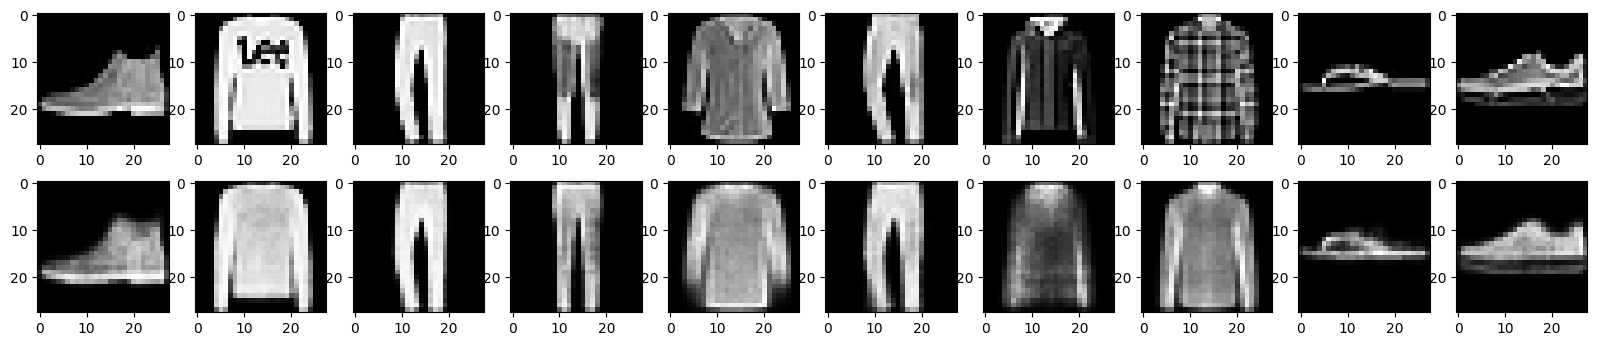

In [71]:
# 4. Visualize the reconstructed images
# Your code here

n=10
plt.figure(figsize=(20,4))
for i in range(n):
    # orignal
    plt.subplot(2, n, i+1)
    plt.imshow(X_test[i].reshape(28,28), cmap='gray')

    # reconstructed
    plt.subplot(2,n, i+1 + n)
    plt.imshow(decoded_imgs[i].reshape(28,28), cmap='gray')

plt.show

In [72]:
# getting the model only for the encoding part
# to get latent space for pca

encoder = ks.Model(input_img, latent_space)
encoder.summary()

X_test_encoded = encoder.predict(X_test)

Model: "functional_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_65 (Dense)                │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_66 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,874 (1.79 MB)

 Trainable params: 468,874 (1.79 MB)

 Non-trainable params: 0 (0.00 B)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 996us/step


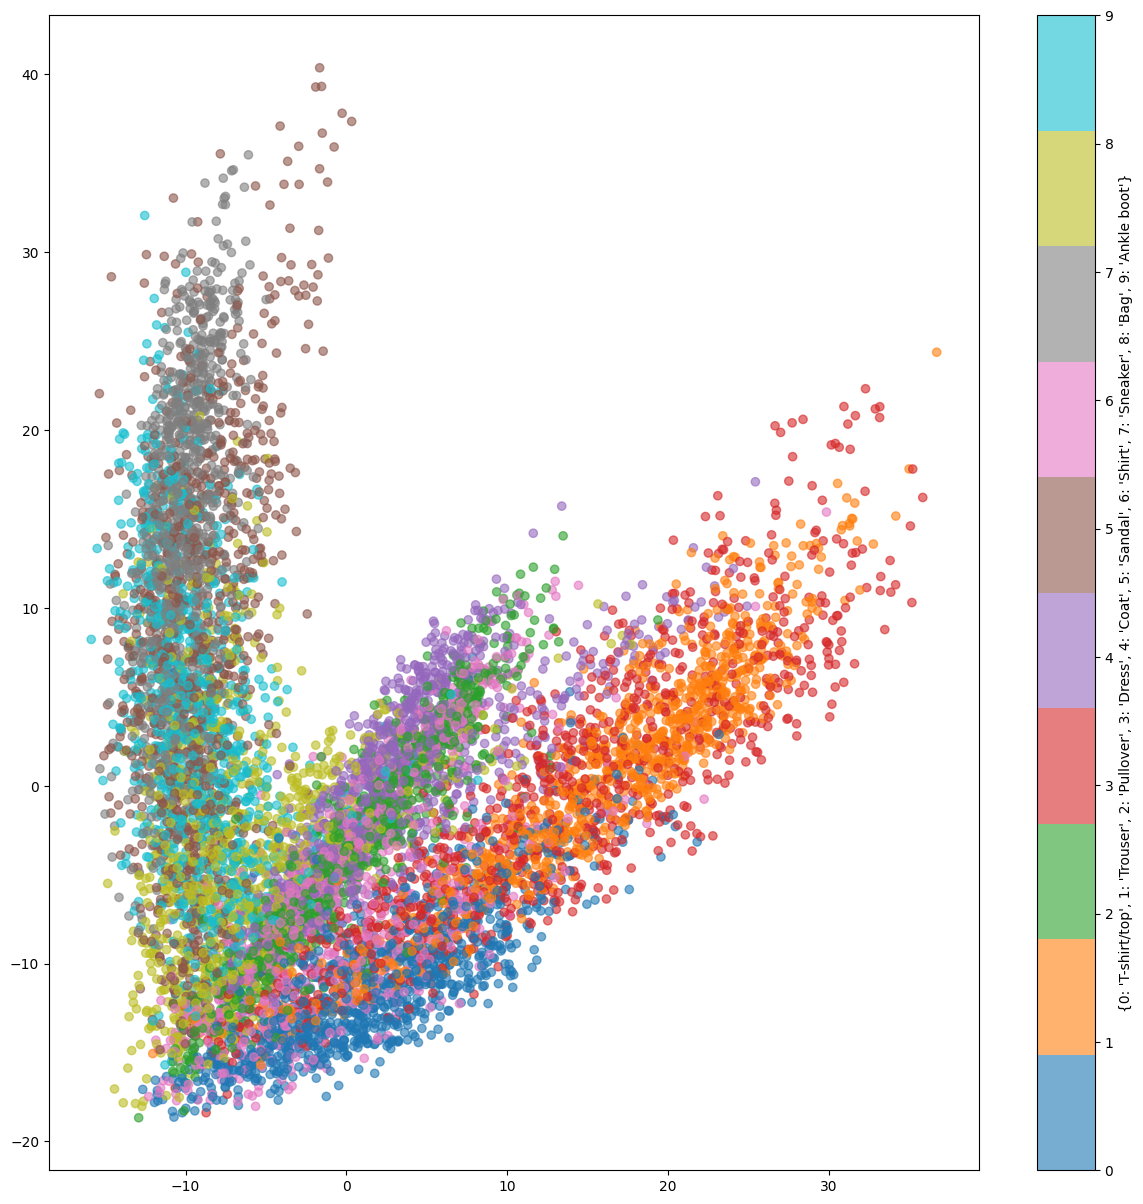

In [73]:
# 4. Visualize the PCA-projection of the latent space. Try to include the labels in the plot for a better understanding of 
# the distribution of the latent space.
# Your code here
pca = PCA(n_components=2)

latent_space_pca = pca.fit_transform(X_test_encoded)

plt.figure(figsize=(15, 15))
plt.scatter(latent_space_pca[:,0], latent_space_pca[:,1], c=y_test, cmap='tab10', alpha=0.6)
# finn ut en måte å se label istedenfor 0-9!!
plt.colorbar(label=label)

**Discussion**
1. Why do we normalize the pixel values of the images?
2. How does the size of the latent space affect the reconstructed images?
3. Can autoencoders be used for noise reduction? How?

In [35]:
# Discuss here

**Answer 1**
We normalize the pixel values to get stabilizing gradients, faster convergence and preventing activation saturation for activation functions like sigmoid.

**Answer 2**
The smaller the size of the latent space gets, the more blurry/worse does the reconstructed images get, and vice versa.

**Answer 3**
Yes, they can be used for noise reduction. Because the lower dimensional latent space have limited capacity to capture noise, they only capture the most structural features.

___
### **Task 2**

In contrast to simple autoencoders, which aim to learn a deterministic mapping from input data to a compressed latent space and back, **Variational Autoencoders (VAEs)** introduce a probabilistic approach to the latent space. While simple autoencoders can reconstruct data effectively, they are not inherently capable of generating new, realistic data samples. VAEs, on the other hand, are designed for _both reconstruction and generation_ of novel data samples, making them highly useful for generative modeling tasks.

**Why VAEs?** A simple autoencoder maps input data to a fixed point in the latent space, meaning that each input has a single corresponding latent vector. While this approach works well for compression and reconstruction, it lacks the ability to generalize and generate new data points because the latent space is not continuous or well-structured.

In contrast, a Variational Autoencoder treats the latent space probabilistically. Instead of mapping each input to a single point, it maps inputs to a distribution (typically a Gaussian distribution) in the latent space. This probabilistic treatment allows for the generation of new samples by sampling from the learned distribution, thus enabling the model to create *new*, unseen data points that resemble the training data.

**How VAEs Work?** In a VAE, the _encoder_ maps the input data to <u>two</u> vectors: a _mean vector_ and a _variance (or log variance) vector_ (in contrast to one as in a traditional AE). These vectors represent a Gaussian distribution in the latent space. Instead of encoding to a fixed point, the model <u>samples</u> a latent vector from this distribution, using these mean and variance parameters. This sampling introduces variability, allowing the VAE to explore different parts of the latent space and generate diverse outputs.

The _decoder_ then reconstructs the data by decoding from the sampled latent vector, which can either come from the encoded input or be randomly generated. This process makes VAEs ideal for generating novel data samples in applications like image generation.

**The loss function?** The loss function plays a crucial role in training the model to both reconstruct input data and ensure that the latent space is properly structured. The VAE loss function consists of two main components:

1. Reconstruction Loss: Measures how well the VAE is able to reconstruct the input data from the latent space. Typically, this is computed using binary cross-entropy (for normalized image data) or mean squared error (for continuous data). For images, binary cross-entropy is often used.

$$\mathcal{L}_{\text{reconstruction}}(x, \hat{x}) = - \sum_{i=1}^{N} \left[ x_i \log(\hat{x}_i) + (1 - x_i) \log(1 - \hat{x}_i) \right]$$

Where:
$x_i$  is the original data point (e.g., pixel value).
$\hat{x}_i$  is the reconstructed data point.
$N$  is the number of data points or pixels.

2. KL Divergence Loss: is used to ensure that the learned latent distribution  $q(z|x)$, parameterized by  $\mu$  and  $\sigma^2$, is close to a standard normal distribution  $p(z) = \mathcal{N}(0, I)$.

$$\mathcal{L}_{\text{KL}}(q(z|x) \parallel p(z)) = -\frac{1}{2} \sum_{j=1}^{d} \left( 1 + \log(\sigma_j^2) - \mu_j^2 - \sigma_j^2 \right)$$
Where:
 $\mu_j$  is the mean of the latent variable distribution. $\sigma_j^2$  is the variance of the latent variable distribution. $d$  is the dimensionality of the latent space.

_Total Loss Function_ The total loss function for a VAE is the sum of the reconstruction loss and the KL divergence loss:
$$\mathcal{L}_{\text{VAE}} = \mathcal{L}_{\text{reconstruction}} + \mathcal{L}_{\text{KL}}$$


**The Role of KL Divergence** A crucial aspect of training VAEs is ensuring that the latent space is well-structured and that the learned distributions align with a _prior distribution_ (typically a standard normal distribution). This is where the _Kullback-Leibler (KL) divergence loss_ comes in. KL divergence measures how different the learned distribution is from the desired prior distribution. By minimizing KL divergence during training, the VAE ensures that the latent space follows a continuous, smooth distribution, making it easier to generate realistic new samples by sampling from this space.

In summary, VAEs combine the strengths of autoencoders for reconstruction with a probabilistic latent space, enabling the generation of new data samples and ensuring smooth interpolation within the latent space through the use of KL divergence. This combination makes VAEs a powerful generative model in unsupervised learning tasks.

<div>
<img src="https://tikz.net/janosh/vae.png" width="350"/>
<div>

Run the following code

In [36]:
import numpy as np
import tensorflow as tf
import keras
from keras import layers, ops
import matplotlib.pyplot as plt

In [37]:
# Load the Fashion-MNIST dataset.
(x_train, _), (x_test, _) = keras.datasets.fashion_mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
# Flatten each 28x28 image to a 784 vector
x_train = x_train.reshape((len(x_train), -1))
x_test = x_test.reshape((len(x_test), -1))

In [38]:
input_dim = x_train.shape[1]  # 784 pixels per image
latent_dim = 2  # Dimensionality of the latent space (small for simplicity, and so that we can plot it)

In [39]:
# We define the encoder in a similar way as the autoencoder
encoder_inputs = layers.Input(shape=(input_dim,))
x = layers.Dense(256, activation="relu")(encoder_inputs)

In [40]:
# However, instead of a single output layer to the latent space, we have two output layers (latent space parameters: mean (mu) and log variance (log_var))
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

In [41]:
# We define a sampling layer to sample from the latent space, which introduces stochasticity in the model and helps in training (as it still allows gradients to flow backwards)
# This is the reparameterization trick: z = mu + sigma * epsilon, where epsilon ~ N(0, I)
class Sampling(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator(1337)

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = ops.shape(z_mean)[0]
        dim = ops.shape(z_mean)[1]
        epsilon = keras.random.normal(shape=(batch, dim), seed=self.seed_generator)
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon

In [42]:
# The Sampling layer takes the learned parameters (mean and log variance) and returns a sampled latent vector z.
# The encoder will output all three: z is passed on to the decoder, while z_mean and z_log_var are used in the loss function
z = Sampling(name="z")([z_mean, z_log_var])

In [43]:
# The decoder is defined in the same way as the autoencoder
decoder_input = layers.Input(shape=(latent_dim,))
x = layers.Dense(256, activation="relu")(decoder_input)
decoded_img = layers.Dense(input_dim, activation="sigmoid")(x)

In a Variational Autoencoder (VAE), adjusting the weight of the KL divergence loss controls the balance between data reconstruction accuracy and latent space regularization. Increasing the weight encourages a more structured and continuous latent space but may reduce reconstruction quality, while decreasing it improves reconstruction but risks losing meaningful structure in the latent space. In the code below, the total loss is $\mathcal{L}_{\text{reconstruction}} + w \cdot \mathcal{L}_{\text{KL}}$, where $w$ is `KL_weight`.

In [104]:
#KL divergence loss weight. This is a hyperparameter that can be tuned, run ALL cells below to see the effect of different values.
# This is the value you should experiment with
KL_weight = 0.1

In [105]:
# Having built our layers, we can now define the models.
# clone_model gives the models fresh (untrained) weights every time this cell is run,
# so each KL_weight experiment starts from scratch.
encoder = keras.models.clone_model(keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder"))
decoder = keras.models.clone_model(keras.Model(decoder_input, decoded_img, name="decoder"))

In [106]:
# VAE model that connects the encoder and decoder, with the VAE loss: Reconstruction loss + KL divergence.
# We write our own train_step, because the loss depends on z_mean and z_log_var, not only on the input and output.
class VAE(keras.Model):
    def __init__(self, encoder, decoder, kl_weight=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.kl_weight = kl_weight
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs):
        """Forward pass (used for inference/predict)."""
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

    def compute_losses(self, data):
        """Shared logic for train/test step."""
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)

        # Reconstruction loss: binary cross-entropy summed over the 784 pixels -> one value per image
        reconstruction_loss = ops.sum(
            ops.binary_crossentropy(data, reconstruction), axis=-1
        )
        # KL divergence between q(z|x) = N(mu, sigma^2) and the prior p(z) = N(0, I) -> one value per image
        kl_loss = -0.5 * ops.sum(
            1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var), axis=-1
        )
        total_loss = ops.mean(reconstruction_loss + self.kl_weight * kl_loss)
        return total_loss, reconstruction_loss, kl_loss

    def _update_metrics(self, total_loss, reconstruction_loss, kl_loss):
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def train_step(self, data):
        if isinstance(data, (tuple, list)):
            data = data[0]
        with tf.GradientTape() as tape:
            total_loss, reconstruction_loss, kl_loss = self.compute_losses(data)

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return self._update_metrics(total_loss, reconstruction_loss, kl_loss)

    def test_step(self, data):
        if isinstance(data, (tuple, list)):
            data = data[0]
        total_loss, reconstruction_loss, kl_loss = self.compute_losses(data)
        return self._update_metrics(total_loss, reconstruction_loss, kl_loss)

In [107]:
# Train the VAE
vae = VAE(encoder, decoder, kl_weight=KL_weight)
vae.compile(optimizer=keras.optimizers.Adam())

history = vae.fit(x_train, epochs=20, batch_size=128, validation_data=(x_test,), verbose=2)

Epoch 1/20
469/469 - 4s - 8ms/step - kl_loss: 41.6859 - loss: 303.9807 - reconstruction_loss: 299.8307 - val_kl_loss: 25.1711 - val_loss: 275.1044 - val_reconstruction_loss: 272.7656
Epoch 2/20
469/469 - 4s - 8ms/step - kl_loss: 21.9080 - loss: 269.8632 - reconstruction_loss: 267.6722 - val_kl_loss: 19.0268 - val_loss: 268.4625 - val_reconstruction_loss: 266.7289
Epoch 3/20
469/469 - 3s - 7ms/step - kl_loss: 18.8440 - loss: 265.3489 - reconstruction_loss: 263.4761 - val_kl_loss: 18.6326 - val_loss: 265.0777 - val_reconstruction_loss: 263.3572
Epoch 4/20
469/469 - 3s - 7ms/step - kl_loss: 17.7289 - loss: 262.8704 - reconstruction_loss: 261.0988 - val_kl_loss: 16.4647 - val_loss: 263.2559 - val_reconstruction_loss: 261.7443
Epoch 5/20
469/469 - 3s - 7ms/step - kl_loss: 16.6423 - loss: 261.3499 - reconstruction_loss: 259.6844 - val_kl_loss: 15.9375 - val_loss: 262.3238 - val_reconstruction_loss: 260.8638
Epoch 6/20
469/469 - 3s - 7ms/step - kl_loss: 15.9444 - loss: 260.3167 - reconstructi

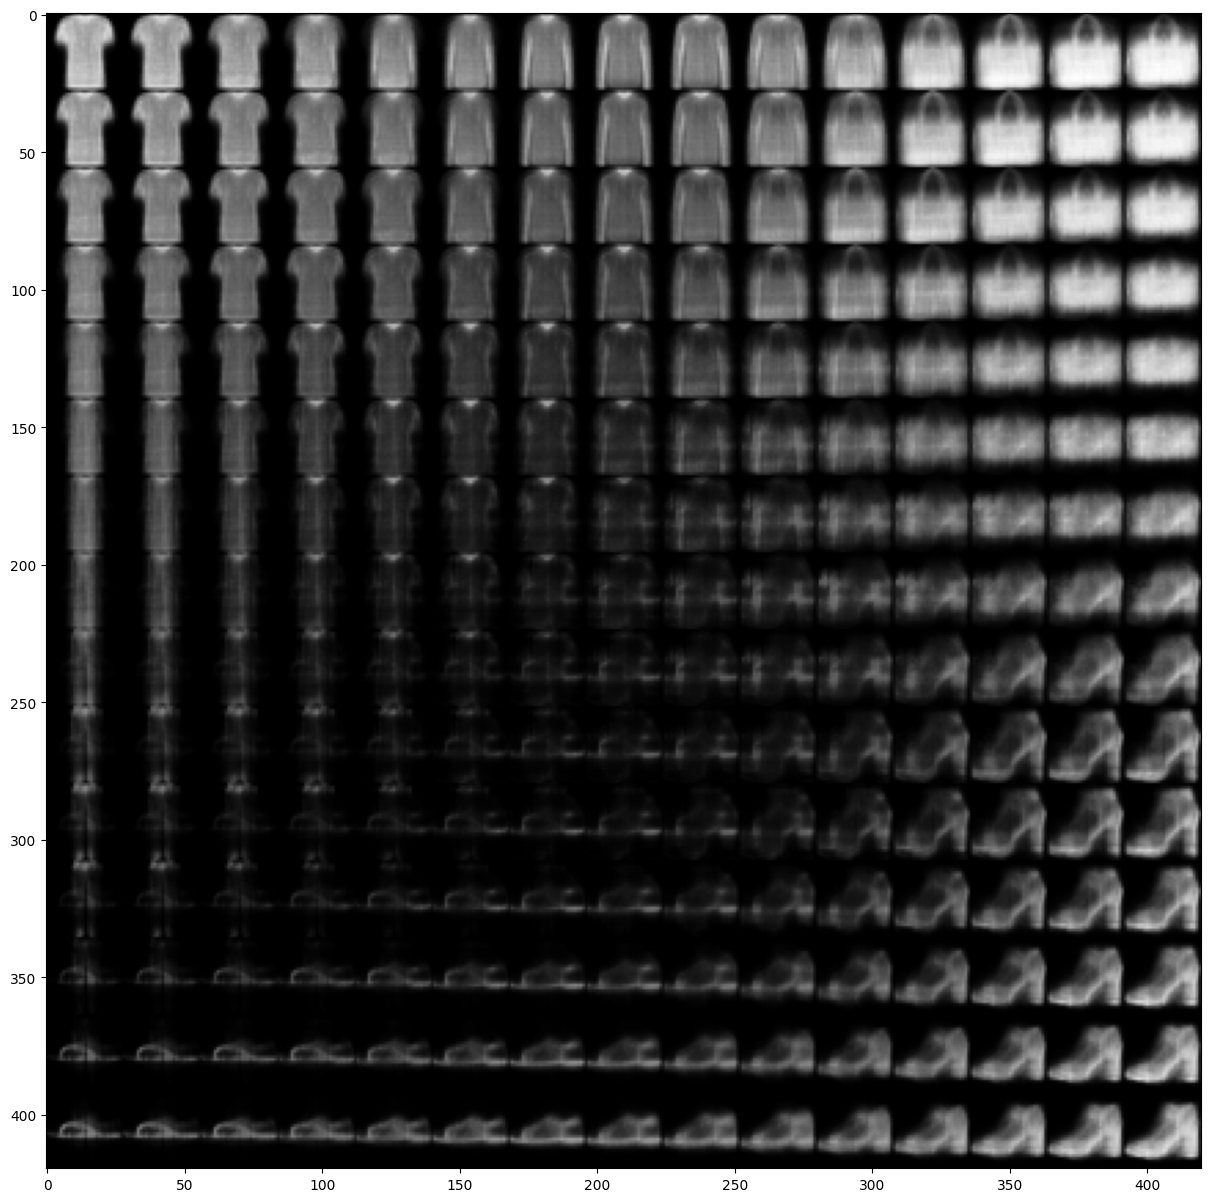

In [94]:
# Run this visualisation code after training the VAE to answer the discussion questions.
def plot_latent_space(decoder, n=15, figsize=15):
    """Plots a grid of clothing items decoded from the VAE's latent space."""
    scale = 2.0
    figure = np.zeros((28 * n, 28 * n))
    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)

    # Decode all n*n grid points in a single call (much faster than one predict per point)
    z_samples = np.array([[xi, yi] for yi in grid_y for xi in grid_x], dtype="float32")
    x_decoded = decoder.predict(z_samples, verbose=0)

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            item = x_decoded[i * n + j].reshape(28, 28)
            figure[i * 28: (i + 1) * 28, j * 28: (j + 1) * 28] = item

    plt.figure(figsize=(figsize, figsize))
    plt.imshow(figure, cmap='Greys_r')
    plt.show()

# Plot latent space
plot_latent_space(decoder)

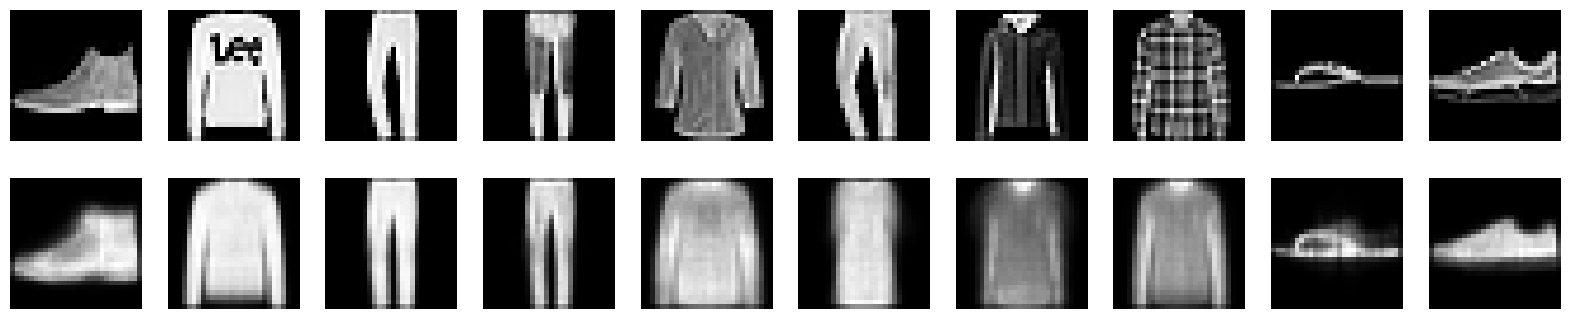

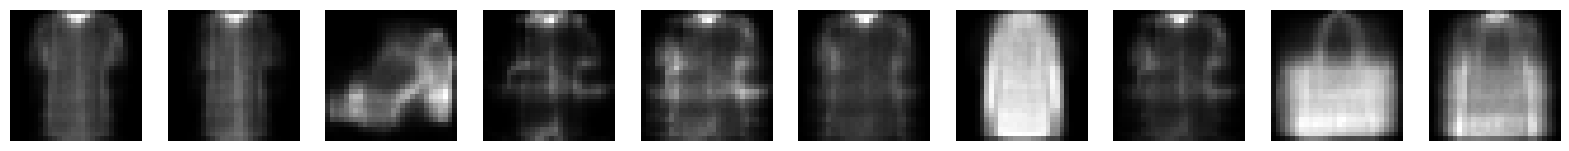

In [95]:
# Run this code to compare original and reconstructed images (top: original, bottom: reconstructed),
# and to generate new images by decoding random points sampled from the prior N(0, I).
test_z_mean, _, _ = vae.encoder.predict(x_test, verbose=0)  # the mean of q(z|x) gives clean, deterministic reconstructions
decoded_imgs = vae.decoder.predict(test_z_mean, verbose=0)

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    ax.axis("off")

    # Reconstructed
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
plt.show()

# Sample new random images
random_latent_vectors = np.random.normal(size=(n, latent_dim)).astype("float32")
generated_images = vae.decoder.predict(random_latent_vectors, verbose=0)

plt.figure(figsize=(20, 2))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    plt.imshow(generated_images[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
plt.show()

**Discussion**

Tips: refer to the visualizations above and the loss output from your training cell (make sure verbose is set to 1 or 2) to answer the questions.

1. Adjust the weight of the KL divergence term in the VAE loss function (e.g., set it to 0.1, 1, and 5). Run the model with each weight setting and observe the results.
2. Based on your observations, discuss how each change in the KL weight affected the VAE’s performance. Were the effects consistent with your expectations, and why or why not? Consider both the quality of the reconstructions, the loss values, and the continuity of the latent space in your answer.

**0.1**
Very blurry and messy information in the plot of the latent space, with a big hole, and the sampling of new random images does not work well. The new random images are blurry and hard to see what clothing it is. The reconstruction is working okay. Reconstruction loss was the lowest for 0.1, but KL loss was the highest of the three.

**1.0**
The plot of the latent space are quite good, with easy to distguish clothing items from each other. Reconstuction is good, and random new images are better than 0.1, but not perfect.
KL loss was in the middle of the two others, and also in the middle for reconstrcution loss.

**5.0**
The plot of the latent space is okay is better than both 0.1 and 1.0. Reconstruction is worse that both 0.1 and 1.0, random new images are better than the rest.
KL loss was the lowest, and reconstruction loss the highest.


**Generall**
It was consistent with our expecations, because with a higher KL weight, the latent space sampling produces sharper images, but worse reconstruction and vice versa.

___